# different datasets

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import nn_bowl
import pandas as pd
import numpy as np
import tqdm

from scipy.stats import t

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [3]:
BREADTH_TICK_VALS = [1.0, 10.0, 100.0]
BREADTH_TICK_TEXT = ["1", "10", "10<sup>2</sup>"]

DEPTH_TICK_VALS = [1.0, 10.0, 100.0]
DEPTH_TICK_TEXT = ["1", "10", "10<sup>2</sup>"]

TIME_TICK_VALS = [0.1, 0.2, 0.5]
TIME_TICK_TEXT = ["0.1", "0.2", "0.5"]

In [4]:
cfg_base = nn_bowl.utils.load_config("config_datasets_v4_train.yaml")
WIDTH = cfg_base.plotting.width.full
nn_bowl.utils.set_plotly_template(cfg_base)
figures_dir = nn_bowl.paths.FIGURES_DIR / "datasets"

# ensuring that all evaluation files exist for all combinations of lam_depth, lam_breadth, lam_time and instance
nn_bowl.utils.ensure_evaluation_files_exist(cfg_base, skip_pruning=False)

ensuring that all evaluation files exist...


100%|██████████| 405/405 [00:31<00:00, 12.89it/s]


In [5]:
model_df = nn_bowl.utils.get_model_df(cfg_base)
model_df["lam_breadth"] = model_df["costs.space.lam_breadth"]
model_df["lam_depth"] = model_df["costs.space.lam_depth"]
model_df["lam_time"] = model_df["costs.time.lam"]
model_df

  1%|          | 5/405 [00:02<02:14,  2.97it/s]

Labels shape for mnist: (10000,)


  8%|▊         | 32/405 [00:04<00:42,  8.83it/s]

Labels shape for cifar10: (10000,)


 13%|█▎        | 53/405 [00:06<00:33, 10.62it/s]

Labels shape for tiny-imagenet: (4923,)


100%|██████████| 405/405 [01:00<00:00,  6.73it/s]


,model_name,dataset,costs.space.lam_breadth,costs.space.lam_depth,costs.time.lam,instance,cost_depth,cost_breadth,cost_time,accuracy,lam_breadth,lam_depth,lam_time
0,dataset=mnist_lam_breadth=1.0_lam_depth=1.0_la...,mnist,1.0,1.0,0.1,0,0.004834,0.001127,0.489171,0.994800,1.0,1.0,0.1
1,dataset=mnist_lam_breadth=1.0_lam_depth=1.0_la...,mnist,1.0,1.0,0.2,0,0.005676,0.001084,0.479604,0.993900,1.0,1.0,0.2
2,dataset=mnist_lam_breadth=1.0_lam_depth=1.0_la...,mnist,1.0,1.0,0.5,0,0.007961,0.001096,0.275847,0.993600,1.0,1.0,0.5
3,dataset=mnist_lam_breadth=1.0_lam_depth=10.0_l...,mnist,1.0,10.0,0.1,0,0.000743,0.001031,0.699227,0.993600,1.0,10.0,0.1
4,dataset=mnist_lam_breadth=1.0_lam_depth=10.0_l...,mnist,1.0,10.0,0.2,0,0.000959,0.001011,0.466647,0.991800,1.0,10.0,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
400,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,10.0,0.2,4,0.003268,0.000137,0.738207,0.332724,100.0,10.0,0.2
401,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,10.0,0.5,4,0.001819,0.000085,0.281849,0.241113,100.0,10.0,0.5
402,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,100.0,0.1,4,0.000277,0.000103,1.012313,0.292098,100.0,100.0,0.1
403,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,100.0,0.2,4,0.000254,0.000099,0.655765,0.257363,100.0,100.0,0.2


In [6]:
# pruning results and masks
pruning_results_dfs, pruning_masks = nn_bowl.utils.get_pruning_results_and_masks(cfg_base, model_df)

# Load data needed for this cell
all_layer_channel_norms = nn_bowl.utils.get_layer_channel_norms(cfg_base)

100%|██████████| 405/405 [00:08<00:00, 45.46it/s]


In [7]:
CELL_SIZE = (150, 150)
EPS = 1e-12
CMAP = "Viridis"
lam_time = 0.1
instance = 0

tick_text_dict = {0.0: "0", 1.0: "1", 10.0: "10", 100.0: "10<sup>2</sup>", 1000.0: "10<sup>3</sup>", 10000.0: "10<sup>4</sup>"}

datasets = ["mnist", "cifar10", "tiny-imagenet"]
lam_depths = sorted(model_df["costs.space.lam_depth"].unique())
lam_breadths = sorted(model_df["costs.space.lam_breadth"].unique())

n_rows = len(lam_depths)
n_cols_per_dataset = len(lam_breadths)
n_total_cols = n_cols_per_dataset * len(datasets) + (len(datasets) - 1)

# build column layout with spacers
col_specs = []
for d_idx in range(len(datasets)):
    for _ in range(n_cols_per_dataset):
        col_specs.append({})
    if d_idx < len(datasets) - 1:
        col_specs.append(None)

fig = make_subplots(
    rows=n_rows, cols=n_total_cols,
    horizontal_spacing=0.008, vertical_spacing=0.02,
    specs=[col_specs] * n_rows,
)

# --- Build axis reference map ---
axis_map = {}
for row_idx in range(1, n_rows + 1):
    for col_idx in range(1, n_total_cols + 1):
        try:
            ref = fig.get_subplot(row_idx, col_idx)
            if ref is not None:
                xaxis = ref.xaxis.plotly_name.replace("axis", "")
                yaxis = ref.yaxis.plotly_name.replace("axis", "")
                axis_map[(row_idx, col_idx)] = (xaxis, yaxis)
        except:
            pass

# --- Compute global log-space min/max ---
all_values = []
for key, arr in all_layer_channel_norms.items():
    if arr is not None:
        all_values.append(np.asarray(arr).ravel())
all_values = np.concatenate(all_values)
all_log = np.log10(all_values + EPS)
ZMIN = float(np.nanmin(all_log))
ZMAX = float(np.nanmax(all_log))

candidate_ticks = np.array([1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1000.0, 10000.0])
tick_vals_orig = candidate_ticks[(candidate_ticks >= 10**ZMIN) & (candidate_ticks <= 10**ZMAX)]
tick_vals_log = np.log10(tick_vals_orig)
colorbar_tick_text = [f"10<sup>{int(np.log10(v))}</sup>" for v in tick_vals_orig]

colorbar_added = False
all_shapes = []

for d_idx, dataset in enumerate(datasets):
    col_offset = d_idx * (n_cols_per_dataset + 1)

    for i, lam_depth in enumerate(reversed(lam_depths), start=1):
        for j, lam_breadth in enumerate(lam_breadths, start=1):
            col = col_offset + j

            combo = {
                "costs.space.lam_breadth": lam_breadth,
                "costs.space.lam_depth": lam_depth,
                "costs.time.lam": lam_time,
                "instance": instance,
                "dataset": dataset,
            }
            key = nn_bowl.utils.get_combo_key(combo)
            arr = all_layer_channel_norms.get(key, None)

            if arr is None:
                print(f"Missing data for {key}, inserting empty heatmap.")
                fig.add_trace(go.Heatmap(
                    z=[[np.nan]], colorscale='viridis',
                    zmin=ZMIN, zmax=ZMAX, showscale=False
                ), row=i, col=col)
                continue

            arr_log = np.log10(np.asarray(arr) + EPS)

            # Determine text color based on average brightness of top region
            top_row_mean = arr_log[-1, :].mean()
            mid_val = (ZMIN + ZMAX) / 4
            text_color = "black"  # always dark; the white box below keeps it readable on any background

            show_colorbar = not colorbar_added
            fig.add_trace(go.Heatmap(
                z=arr_log,
                colorscale=CMAP,
                zmin=ZMIN, zmax=ZMAX,
                showscale=show_colorbar,
                colorbar=dict(
                    title=dict(text="avg.<br>weight<br>magnitude",
                               font=dict(size=cfg_base.plotting.font.size)),
                    len=0.9, thickness=10, y=0.75, outlinewidth=0,
                    tickvals=tick_vals_log, ticktext=colorbar_tick_text,
                ) if show_colorbar else None,
                hovertemplate=(
                    "layer=%{y}<br>"
                    "channel=%{x}<br>"
                    "log10(norm)=%{z:.3f}"
                    "<extra></extra>"
                ),
            ), row=i, col=col)
            if show_colorbar:
                colorbar_added = True

            # Get domain refs for annotations
            if (i, col) in axis_map:
                xref_d = axis_map[(i, col)][0] + " domain"
                yref_d = axis_map[(i, col)][1] + " domain"

                # Accuracy annotation (top-right, matching breadth_depth style)
                pruning_df = pruning_results_dfs.get(key)
                if pruning_df is not None:
                    baseline_accuracy = pruning_df[pruning_df["phase"] == "baseline"]["accuracy"].values[0]
                    final_accuracy = pruning_df[pruning_df["threshold_hit"] == False]["accuracy"].values[-1]
                    fig.add_annotation(
                        x=0.98, y=0.98,
                        xref=xref_d, yref=yref_d,
                        text=f"{baseline_accuracy:.1%}→{final_accuracy:.1%}",
                        showarrow=False,
                        font=dict(size=8, color=text_color),
                        bgcolor="rgba(255,255,255,0.8)", borderpad=1,
                        xanchor="right", yanchor="top",
                    )

                # Y-axis lambda labels (left side of each dataset group)
                if j == 1:
                    fig.add_annotation(
                        x=-0.6, y=0.5,
                        xref=xref_d, yref=yref_d,
                        text=tick_text_dict[lam_depth],
                        showarrow=False,
                        font=dict(size=cfg_base.plotting.font.size),
                    )

                # X-axis lambda labels (bottom)
                if i == n_rows:
                    fig.add_annotation(
                        x=0.5, y=-0.7,
                        xref=xref_d, yref=yref_d,
                        text=tick_text_dict[lam_breadth],
                        showarrow=False,
                        font=dict(size=cfg_base.plotting.font.size),
                    )

            # tick labels
            is_bottom_row = (i == n_rows)
            is_left_col_local = (j == 1)

            fig.update_xaxes(
                showticklabels=is_bottom_row,
                ticks="outside" if is_bottom_row else "",
                tickvals=[0, 15, 31, 47],
                ticktext=["1", "16", "32", "48"],
                tickfont_size=6,
                title_text="",
                row=i, col=col,
            )
            fig.update_yaxes(
                showticklabels=is_left_col_local,
                ticks="outside" if is_left_col_local else "",
                tickvals=[0, 1, 2, 3, 4, 5],
                ticktext=["1", "2", "3", "4", "5", "6"],
                tickfont_size=6,
                title_text="",
                row=i, col=col,
            )

            # pruning boundary shapes
            mask_arr = pruning_masks.get(key)
            if mask_arr is not None and (i, col) in axis_map:
                xref_data, yref_data = axis_map[(i, col)]
                boundary_shapes = nn_bowl.utils.mask_boundary_shapes(mask_arr, color="red", width=2)
                for s in boundary_shapes:
                    s["xref"] = xref_data
                    s["yref"] = yref_data
                    all_shapes.append(s)

fig.update_layout(shapes=all_shapes)

# "channel" and "layer" labels on bottom-left subplot of each dataset
for d_idx, dataset in enumerate(datasets):
    col = d_idx * (n_cols_per_dataset + 1) + 1
    if (n_rows, col) in axis_map:
        xref_d = axis_map[(n_rows, col)][0] + " domain"
        yref_d = axis_map[(n_rows, col)][1] + " domain"
        fig.add_annotation(
            x=0.5, y=-0.4, xref=xref_d, yref=yref_d,
            text="channel", showarrow=False, font=dict(size=12),
        )
        fig.add_annotation(
            x=-0.4, y=0.5, xref=xref_d, yref=yref_d,
            text="layer", showarrow=False, font=dict(size=12), textangle=-90,
        )

# Dataset titles
fig.add_annotation(x=0.1, y=1.4, xref="paper", yref="paper", text=f"<b>MNIST</b>", showarrow=False,font=dict(size=cfg_base.plotting.font.size))
fig.add_annotation(x=0.5, y=1.4, xref="paper", yref="paper", text=f"<b>CIFAR-10</b>", showarrow=False,font=dict(size=cfg_base.plotting.font.size))
fig.add_annotation(x=0.95, y=1.4, xref="paper", yref="paper", text=f"<b>Tiny ImageNet</b>", showarrow=False,font=dict(size=cfg_base.plotting.font.size))


# Global axis labels
fig.add_annotation(x=0.5, y=-0.32, xref="paper", yref="paper",
                   text="λ<sub>breadth</sub> →", showarrow=False,
                   font=dict(size=cfg_base.plotting.font.size))
fig.add_annotation(x=-0.09, y=0.5, xref="paper", yref="paper",
                   text="λ<sub>depth</sub> →", showarrow=False,
                   font=dict(size=cfg_base.plotting.font.size), textangle=-90)

# Pruned model legend
pruned_model_x = 1.03
pruned_model_y = 0.02
fig.add_annotation(
    x=pruned_model_x, y=pruned_model_y,
    xref="paper", yref="paper",
    text="pruned<br>model", showarrow=False,
    font=dict(size=cfg_base.plotting.font.size),
    align="left", xanchor="left",
)
fig.add_annotation(
    x=pruned_model_x, y=pruned_model_y - 0.13,
    xref="paper", yref="paper",
    text="98% above-chance<br>accuracy preserved", showarrow=False,
    font=dict(size=10),
    align="left", xanchor="left",
)
fig.add_shape(
    type="rect",
    x0=pruned_model_x + 0.08, x1=pruned_model_x + 0.12, y0=pruned_model_y+0.06, y1=pruned_model_y + 0.14,
    xref="paper", yref="paper",
    line=dict(color="red", width=3),
    fillcolor="rgba(0,0,0,0)",
)

fig.update_layout(
    margin=dict(l=80, r=150, t=100, b=80),
    height=WIDTH * 0.4, width=WIDTH,
)
fig.show()

nn_bowl.utils.save_figure(fig, figures_dir, "datasets_breadth_depth_layer_channel_norms_grid", scale=4)

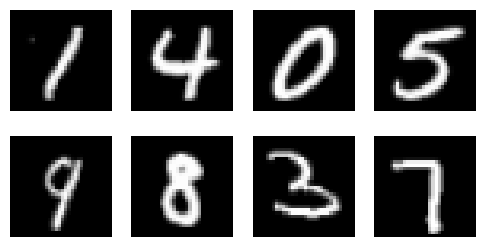

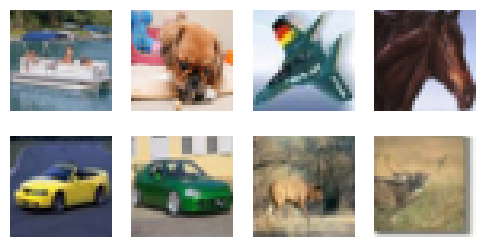

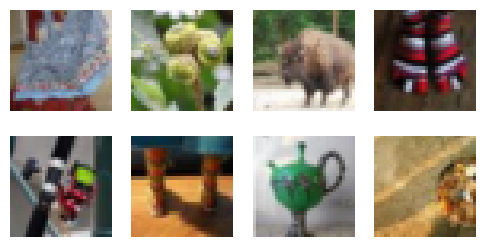

In [8]:
import matplotlib.pyplot as plt
import numpy as np

for dataset_name in datasets:
    cfg_dataset = cfg_base.copy()
    cfg_dataset.dataset.name = dataset_name
    dataset = nn_bowl.utils.get_dataloaders(cfg_dataset)["test"].dataset
    # select random 8 images
    np.random.seed(200)
    indices = np.random.permutation(len(dataset))[:8]

    # plt the images in a 2x4 grid
    fig, axes = plt.subplots(2, 4, figsize=(6, 3))
    for idx, ax in zip(indices, axes.flatten()):
        img = dataset[int(idx)]["img"]
        # denormalize
        img = nn_bowl.utils.denormalize(img, dataset_name=dataset_name)
        img = img.permute(1, 2, 0).numpy()  # CHW to HWC

        ax.imshow(img)
        # ax.set_title(f"label: {label}")
        ax.axis("off")

    plt.savefig(figures_dir / f"{dataset_name}_sample_images.png", bbox_inches="tight")

In [9]:
# add all resources used
def add_layers_channels_used(model_df_row):
    lam_breadth = model_df_row["lam_breadth"]
    lam_depth = model_df_row["lam_depth"]
    lam_time = model_df_row["lam_time"]
    instance = model_df_row["instance"]

    combo = {
        "costs.space.lam_breadth": lam_breadth,
        "costs.space.lam_depth": lam_depth,
        "costs.time.lam": lam_time,
        "dataset": model_df_row["dataset"],
        "instance": instance,
    }
    key = nn_bowl.utils.get_combo_key(combo)
    mask = pruning_masks.get(key)
    layers_used = np.sum(np.sum(mask, axis=1) > 0)  # count how many layers have at least one channel used
    channels_used = np.sum(mask) / layers_used

    model_df_row["layers_used"] = layers_used
    model_df_row["channels_used"] = channels_used

    return model_df_row

def get_time_used(row):
    time_used = 0.0
    n_timesteps = len([c for c in row.index if c.startswith("t_")])
    for t in range(n_timesteps):
        time_used += row[f"t_{t}"] * (t + 1)
    return time_used


print("Loading pruning results and masks...")
pruning_results_dfs, pruning_masks = nn_bowl.utils.get_pruning_results_and_masks(cfg_base, model_df)
print("Loading time df...")
time_df = nn_bowl.utils.get_time_df(cfg_base, model_df)

# layers and channels used
print("Calculating layers and channels used...")
model_df = model_df.apply(add_layers_channels_used, axis=1)

# time used
print("Calculating time used...")
time_used_df = time_df.pivot_table(
    index=[c for c in time_df.columns if c not in ("t", "t_weight")],
    columns="t",
    values="t_weight",
).reset_index()
time_used_df.columns = [f"t_{c}" if isinstance(c, (int, np.integer)) else c for c in time_used_df.columns]
time_used_df["time_used"] = time_used_df.apply(get_time_used, axis=1)

time_used_agg = time_used_df.groupby(
    ["dataset", "costs.space.lam_breadth", "costs.space.lam_depth", "costs.time.lam", "instance"]
)["time_used"].mean().reset_index()

model_df = model_df.merge(time_used_agg, 
    on=["dataset", "costs.space.lam_breadth", "costs.space.lam_depth", "costs.time.lam", "instance"],
    how="left",
)
model_df

Loading pruning results and masks...
Loading time df...


100%|██████████| 405/405 [00:08<00:00, 45.38it/s]


Calculating layers and channels used...
Calculating time used...


,model_name,dataset,costs.space.lam_breadth,costs.space.lam_depth,costs.time.lam,instance,cost_depth,cost_breadth,cost_time,accuracy,lam_breadth,lam_depth,lam_time,layers_used,channels_used,time_used
0,dataset=mnist_lam_breadth=1.0_lam_depth=1.0_la...,mnist,1.0,1.0,0.1,0,0.004834,0.001127,0.489171,0.994800,1.0,1.0,0.1,6,18.833333,1.956684
1,dataset=mnist_lam_breadth=1.0_lam_depth=1.0_la...,mnist,1.0,1.0,0.2,0,0.005676,0.001084,0.479604,0.993900,1.0,1.0,0.2,6,20.333333,1.918417
2,dataset=mnist_lam_breadth=1.0_lam_depth=1.0_la...,mnist,1.0,1.0,0.5,0,0.007961,0.001096,0.275847,0.993600,1.0,1.0,0.5,6,23.666667,1.103390
3,dataset=mnist_lam_breadth=1.0_lam_depth=10.0_l...,mnist,1.0,10.0,0.1,0,0.000743,0.001031,0.699227,0.993600,1.0,10.0,0.1,4,18.750000,2.796908
4,dataset=mnist_lam_breadth=1.0_lam_depth=10.0_l...,mnist,1.0,10.0,0.2,0,0.000959,0.001011,0.466647,0.991800,1.0,10.0,0.2,4,21.000000,1.866588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
400,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,10.0,0.2,4,0.003268,0.000137,0.738207,0.332724,100.0,10.0,0.2,6,17.166667,2.952827
401,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,10.0,0.5,4,0.001819,0.000085,0.281849,0.241113,100.0,10.0,0.5,5,17.000000,1.127397
402,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,100.0,0.1,4,0.000277,0.000103,1.012313,0.292098,100.0,100.0,0.1,5,12.000000,4.049251
403,dataset=tiny-imagenet_lam_breadth=100.0_lam_de...,tiny-imagenet,100.0,100.0,0.2,4,0.000254,0.000099,0.655765,0.257363,100.0,100.0,0.2,4,14.250000,2.623062


In [10]:
model_df.groupby("dataset").agg(
    layers_used_mean=pd.NamedAgg(column="layers_used", aggfunc="mean"),
    channels_used_mean=pd.NamedAgg(column="channels_used", aggfunc="mean"),
    time_used_mean=pd.NamedAgg(column="time_used", aggfunc="mean"),
    layers_used_std=pd.NamedAgg(column="layers_used", aggfunc="std"),
    channels_used_std=pd.NamedAgg(column="channels_used", aggfunc="std"),
    time_used_std=pd.NamedAgg(column="time_used", aggfunc="std"),
)

,layers_used_mean,channels_used_mean,time_used_mean,layers_used_std,channels_used_std,time_used_std
dataset,,,,,,
cifar10,5.133333,23.420000,3.530785,0.998506,5.774448,1.260652
mnist,4.748148,15.960864,2.104820,1.336729,4.428172,0.632556
tiny-imagenet,5.207407,24.140617,2.819922,1.140151,7.260543,1.317505


In [11]:
dataset_order = ["mnist", "cifar10", "tiny-imagenet"]
DATASET_LABELS = {"mnist": "MNIST", "cifar10": "CIFAR-10", "tiny-imagenet": "Tiny ImageNet"}  # display names
dataset_dashes = {
    "mnist": "solid",
    "cifar10": "dash",
    "tiny-imagenet": "dot",
}
dataset_symbols = {
    "mnist": "circle",
    "cifar10": "square",
    "tiny-imagenet": "diamond",
}

resources = [
    ("channels_used", "channels used", "lam_breadth", cfg_base.plotting.breadth),
    ("layers_used", "layers used", "lam_depth", cfg_base.plotting.depth),
    ("time_used", "time used", "lam_time", cfg_base.plotting.time),
]


n = cfg_base.experiment.n_instances
multiplier = t.ppf(0.975, df=n - 1)

fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.12,
                    subplot_titles=["channels used", "layers used", "time used"])

for dataset in reversed(dataset_order):
    fig.add_trace(go.Scatter(
        x=[None], y=[None],
        mode="lines+markers",
        marker=dict(size=7, symbol=dataset_symbols[dataset], color="black"),
        line=dict(color="black", width=2, dash=dataset_dashes[dataset]),
        name=DATASET_LABELS[dataset],
        # showlegend=True,
        showlegend=False,
    ), row=1, col=1)

for i, (resource_col, ylabel, lam_col, color) in enumerate(resources):
    instance_means = model_df.groupby(["dataset", lam_col, "instance"])[resource_col].mean().reset_index()
    stats = instance_means.groupby(["dataset", lam_col])[resource_col].agg(["mean", "std"]).reset_index()

    for dataset in dataset_order:

        ds_stats = stats[stats["dataset"] == dataset].sort_values(lam_col)
        sems = multiplier * ds_stats["std"] / np.sqrt(n)

        fig.add_trace(go.Scatter(
            x=ds_stats[lam_col],
            y=ds_stats["mean"],
            error_y=dict(type="data", array=sems, visible=True),
            mode="lines+markers",
            marker=dict(size=7, symbol=dataset_symbols[dataset]),
            line=dict(color=color, width=2, dash=dataset_dashes[dataset]),
            name=DATASET_LABELS[dataset],
            showlegend=False,
        ), row=1, col=i + 1)

    fig.update_xaxes(
        title_text=f"λ<sub>{lam_col.replace('lam_', '')}</sub>",
        type="category",
        row=1, col=i + 1,
        title_standoff=0,
    )
    fig.update_yaxes(title_text=ylabel, row=1, col=i + 1, title_standoff=2)

fig.update_layout(
    width=WIDTH * 0.45,
    height=WIDTH * 0.25,
    margin=dict(l=50, r=10, t=40, b=50),
    showlegend=True,
)
fig.show()

nn_bowl.utils.save_figure(fig, figures_dir, "datasets_resources_used_by_lambda", scale=4)

In [12]:
dataset_order = ["mnist", "cifar10", "tiny-imagenet"]
DATASET_LABELS = {"mnist": "MNIST", "cifar10": "CIFAR-10", "tiny-imagenet": "Tiny ImageNet"}  # display names
dataset_dashes = {
    "mnist": "solid",
    "cifar10": "dash",
    "tiny-imagenet": "dot",
}
dataset_symbols = {
    "mnist": "circle",
    "cifar10": "square",
    "tiny-imagenet": "diamond",
}

chance_acc = {
    "mnist": 0.1,
    "cifar10": 0.1,
    "tiny-imagenet": 0.005,
}

resources = [
    ("channels_used", "channels used", "lam_breadth", cfg_base.plotting.breadth),
    ("layers_used", "layers used", "lam_depth", cfg_base.plotting.depth),
    ("time_used", "time used", "lam_time", cfg_base.plotting.time),
]

n = cfg_base.experiment.n_instances
multiplier = t.ppf(0.975, df=n - 1)

fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.12,
                    subplot_titles=["channels used", "layers used", "time used"])

for dataset in reversed(dataset_order):
    fig.add_trace(go.Scatter(
        x=[None], y=[None],
        mode="lines+markers",
        marker=dict(size=7, symbol=dataset_symbols[dataset], color="black"),
        line=dict(color="black", width=2, dash=dataset_dashes[dataset]),
        name=DATASET_LABELS[dataset],
        showlegend=True,
    ), row=1, col=1)

for i, (resource_col, ylabel, lam_col, color) in enumerate(resources):
    instance_means = model_df.groupby(["dataset", lam_col, "instance"]).agg(
        resource_mean=(resource_col, "mean"),
        accuracy_mean=("accuracy", "mean"),
    ).reset_index()

    # compute kappa and efficiency per instance
    instance_means["chance"] = instance_means["dataset"].map(chance_acc)
    instance_means["kappa"] = (instance_means["accuracy_mean"] - instance_means["chance"]) / (1 - instance_means["chance"])
    instance_means["kappa"] = instance_means["kappa"].clip(lower=1e-6)  # avoid division by zero
    instance_means["efficiency"] = instance_means["kappa"] / instance_means["resource_mean"]  # efficiency is kappa per unit resource

    stats = instance_means.groupby(["dataset", lam_col])["efficiency"].agg(["mean", "std"]).reset_index()

    for dataset in dataset_order:
        ds_stats = stats[stats["dataset"] == dataset].sort_values(lam_col)
        sems = multiplier * ds_stats["std"] / np.sqrt(n)
        fig.add_trace(go.Scatter(
            x=ds_stats[lam_col],
            y=ds_stats["mean"],
            error_y=dict(type="data", array=sems, visible=True),
            mode="lines+markers",
            marker=dict(size=7, symbol=dataset_symbols[dataset]),
            line=dict(color=color, width=2, dash=dataset_dashes[dataset]),
            name=DATASET_LABELS[dataset],
            showlegend=False,
        ), row=1, col=i + 1)

    fig.update_yaxes(title_text=f"κ / {ylabel} ", row=1, col=i + 1, title_standoff=2)
     

    fig.update_xaxes(
        title_text=f"λ<sub>{lam_col.replace('lam_', '')}</sub>",
        type="category",
        row=1, col=i + 1,
        title_standoff=0,
    )

fig.update_layout(
    width=WIDTH * 0.55,
    height=WIDTH * 0.25,
    margin=dict(l=50, r=10, t=40, b=50),
    showlegend=True,
)
fig.update_layout(
    legend=dict(font=dict(size=14))
)
fig.show()

nn_bowl.utils.save_figure(fig, figures_dir, "datasets_efficiency_by_lambda", scale=4)



In [13]:
# Marginal returns: how much does one more unit of a resource reduce the task loss, in the units the optimizer sees?
# Training minimizes L_task = CE / log K (nn_bowl/costs/error_cost.py) plus resource costs, so a network stops growing
# when one more unit of resource reduces L_task by less than it adds in cost. Fig 6c (kappa / resource) is an *average*
# return; this cell estimates the *marginal* return: the slope of L_task against resources used as lambda varies.
#
# For each dataset and resource, within each instance, we hold the other two lambdas fixed (9 groups) and regress
# L_task on resources used across the 3 values of that resource's lambda (fixed-effects slope: both sides demeaned within
# group). Slopes are then averaged over instances (mean, 95% t-CI across the 5 instances). "Gain" = -slope.
from scipy.stats import t as t_dist, ttest_ind

N_CLASSES = {"mnist": 10, "cifar10": 10, "tiny-imagenet": 200}

# --- test cross-entropy per model (same evaluation as the accuracies: results.npz, noise on) ---
ce_rows = []
for _, row in tqdm.tqdm(model_df.iterrows(), total=len(model_df), desc="Loading test cross-entropy"):
    combo = nn_bowl.utils.get_combo_from_row(cfg_base, row)
    cfg = nn_bowl.utils.get_cfg(cfg_base, combo)
    res = np.load(nn_bowl.utils.get_results_dir(cfg) / "results.npz")
    probs, labels = res["probs"], res["labels"]
    ce = -np.mean(np.log(probs[np.arange(len(labels)), labels] + 1e-8))  # same epsilon as training
    ce_rows.append(ce)
model_df["test_ce"] = ce_rows
model_df["L_task"] = model_df["test_ce"] / model_df["dataset"].map(lambda d: np.log(N_CLASSES[d]))
model_df["accuracy_pct"] = model_df["accuracy"] * 100

lam_cols = ["lam_breadth", "lam_depth", "lam_time"]
marginal_resources = [
    ("channels_used", "lam_breadth", "channel"),
    ("layers_used", "lam_depth", "layer"),
    ("time_used", "lam_time", "time step"),
]
# (column, label, sign): gain = sign * slope, so a positive gain always means "one more unit helps"
outcomes = [
    ("L_task", "reduction in L_task (CE / log K)", -1),   # what the optimizer trades off
    ("test_ce", "reduction in CE (nats)", -1),           # without the log K normalization
    ("accuracy_pct", "increase in accuracy (points)", +1),
]

def fe_slope(df, y_col, x_col, group_cols):
    """Within-group (fixed-effects) OLS slope of y on x."""
    x = df[x_col] - df.groupby(group_cols)[x_col].transform("mean")
    y = df[y_col] - df.groupby(group_cols)[y_col].transform("mean")
    return float((x * y).sum() / (x * x).sum())

slope_rows = []
for res_col, lam_col, unit in marginal_resources:
    other_lams = [c for c in lam_cols if c != lam_col]
    for dataset in ["mnist", "cifar10", "tiny-imagenet"]:
        for inst in sorted(model_df["instance"].unique()):
            d = model_df[(model_df["dataset"] == dataset) & (model_df["instance"] == inst)]
            row = dict(resource=res_col, unit=unit, dataset=dataset, instance=inst,
                       resource_range=f"{d.groupby(lam_col)[res_col].mean().min():.2f}–{d.groupby(lam_col)[res_col].mean().max():.2f}")
            for y_col, _, _ in outcomes:
                row[y_col] = fe_slope(d, y_col, res_col, other_lams)
            slope_rows.append(row)
slopes = pd.DataFrame(slope_rows)

def summarize(slopes, y_col, sign):
    g = (sign * slopes[y_col]).groupby([slopes["resource"], slopes["dataset"]])
    out = g.agg(["mean", "std", "count"]).reset_index()
    half = t_dist.ppf(0.975, out["count"] - 1) * out["std"] / np.sqrt(out["count"])
    out["gain_per_unit"] = out["mean"]
    out["ci_low"], out["ci_high"] = out["mean"] - half, out["mean"] + half
    return out

print("Marginal gain per unit of resource (mean [95% CI] across instances; positive = more resource helps)\n")
marginal_summary = {}
for y_col, label, sign in outcomes:
    s = summarize(slopes, y_col, sign)
    marginal_summary[y_col] = s
    print(f"--- {label} per unit")
    for res_col, _, unit in marginal_resources:
        parts = []
        for dataset in ["mnist", "cifar10", "tiny-imagenet"]:
            r = s[(s["resource"] == res_col) & (s["dataset"] == dataset)].iloc[0]
            parts.append(f"{dataset}: {r.gain_per_unit:+.4f} [{r.ci_low:+.4f}, {r.ci_high:+.4f}]")
        c = sign * slopes[(slopes["resource"] == res_col) & (slopes["dataset"] == "cifar10")][y_col]
        ti = sign * slopes[(slopes["resource"] == res_col) & (slopes["dataset"] == "tiny-imagenet")][y_col]
        p = ttest_ind(ti, c, equal_var=False).pvalue
        print(f"  per {unit:9s} | " + " | ".join(parts) + f" | Tiny/CIFAR ratio {ti.mean() / c.mean():.2f}, Welch p = {p:.3g}")
    print()

print("Resource range spanned by the lambda grid (mean over instances of per-lambda means):")
print(slopes.groupby(["resource", "dataset"])["resource_range"].first().unstack().to_string(), "\n")

# time cost is linear in time used: L_time = lam_time * time_used / (T - 1), so at an interior optimum the marginal
# reduction in L_task per extra time step should be about lam_time / (T - 1) -- the same price for every dataset
T = cfg_base.model.n_timesteps
print("Price of one time step in L_task units, lam_time / (T-1):",
      {lt: round(lt / (T - 1), 4) for lt in sorted(model_df["lam_time"].unique())})

# --- figure: L_task vs resources used, one point per lambda value (mean over other lambdas and instances) ---
dataset_symbols = {"mnist": "circle", "cifar10": "square", "tiny-imagenet": "diamond"}
dataset_dashes = {"mnist": "solid", "cifar10": "dash", "tiny-imagenet": "dot"}
DATASET_LABELS = {"mnist": "MNIST", "cifar10": "CIFAR-10", "tiny-imagenet": "Tiny ImageNet"}
colors = {"channels_used": cfg_base.plotting.breadth, "layers_used": cfg_base.plotting.depth, "time_used": cfg_base.plotting.time}
n_inst = cfg_base.experiment.n_instances
mult = t_dist.ppf(0.975, df=n_inst - 1)

fig_marg = make_subplots(rows=1, cols=3, horizontal_spacing=0.1, shared_yaxes=False)
for dataset in ["mnist", "cifar10", "tiny-imagenet"]:
    fig_marg.add_trace(go.Scatter(
        x=[None], y=[None], mode="lines+markers", name=DATASET_LABELS[dataset],
        marker=dict(symbol=dataset_symbols[dataset], color="black", size=7),
        line=dict(color="black", dash=dataset_dashes[dataset]), showlegend=True,
    ), row=1, col=1)
for col, (res_col, lam_col, unit) in enumerate(marginal_resources, start=1):
    for dataset in ["mnist", "cifar10", "tiny-imagenet"]:
        d = model_df[model_df["dataset"] == dataset]
        per_inst = d.groupby([lam_col, "instance"])[[res_col, "L_task"]].mean().reset_index()
        agg = per_inst.groupby(lam_col).agg(x=(res_col, "mean"), x_sd=(res_col, "std"),
                                            y=("L_task", "mean"), y_sd=("L_task", "std")).reset_index()
        fig_marg.add_trace(go.Scatter(
            x=agg["x"], y=agg["y"],
            error_x=dict(type="data", array=mult * agg["x_sd"] / np.sqrt(n_inst), thickness=1, width=2),
            error_y=dict(type="data", array=mult * agg["y_sd"] / np.sqrt(n_inst), thickness=1, width=2),
            mode="lines+markers",
            marker=dict(symbol=dataset_symbols[dataset], color=colors[res_col], size=7),
            line=dict(color=colors[res_col], dash=dataset_dashes[dataset]),
            showlegend=False,
        ), row=1, col=col)
    fig_marg.update_xaxes(title_text=res_col.replace("_", " "), row=1, col=col)
    # linear y: the comparison is about absolute changes in L_task per unit of resource (the slope the optimizer sees)
    fig_marg.update_yaxes(title_text="L<sub>task</sub> (CE / log K)" if col == 1 else None, rangemode="tozero", row=1, col=col)
fig_marg.update_layout(width=WIDTH * 0.8, height=WIDTH * 0.28, margin=dict(l=60, r=10, t=20, b=50),
                       showlegend=True, legend=dict(font=dict(size=12)))
fig_marg.show()
nn_bowl.utils.save_figure(fig_marg, figures_dir, "datasets_marginal_returns", scale=2)

Loading test cross-entropy: 100%|██████████| 405/405 [00:15<00:00, 25.41it/s]


Marginal gain per unit of resource (mean [95% CI] across instances; positive = more resource helps)

--- reduction in L_task (CE / log K) per unit
  per channel   | mnist: +0.0003 [+0.0003, +0.0004] | cifar10: +0.0048 [+0.0042, +0.0054] | tiny-imagenet: +0.0041 [+0.0038, +0.0043] | Tiny/CIFAR ratio 0.85, Welch p = 0.0219
  per layer     | mnist: +0.0029 [+0.0026, +0.0032] | cifar10: +0.0310 [+0.0271, +0.0350] | tiny-imagenet: +0.0314 [+0.0275, +0.0353] | Tiny/CIFAR ratio 1.01, Welch p = 0.865
  per time step | mnist: +0.0034 [+0.0030, +0.0039] | cifar10: +0.0252 [+0.0244, +0.0260] | tiny-imagenet: +0.0331 [+0.0320, +0.0343] | Tiny/CIFAR ratio 1.31, Welch p = 8.21e-07

--- reduction in CE (nats) per unit
  per channel   | mnist: +0.0008 [+0.0006, +0.0010] | cifar10: +0.0110 [+0.0097, +0.0123] | tiny-imagenet: +0.0216 [+0.0202, +0.0229] | Tiny/CIFAR ratio 1.96, Welch p = 3.12e-07
  per layer     | mnist: +0.0067 [+0.0060, +0.0074] | cifar10: +0.0715 [+0.0623, +0.0806] | tiny-imagenet: +0